# mEC open-field spatial tuning (stage 1, classic scores)

Reads the merged tables and shards of one run of `run_spatial.py --engine of --dataset mec`; it never
opens a data_dic (`RUN_MODE = 'load'`). Write-up: `SPATIAL_TUNING.md`. Galleries of every unit are in the
run's `figures/` folder (`spatial_plots.of_gallery_pdf`).

In [1]:
import os, sys, glob, pickle
import numpy as np, pandas as pd
sys.path.insert(0, os.path.abspath('.'))
import spatial_plots as sp
RUN_MODE = 'load'
RUN = '/ceph/behrens/adam_harris/Taskspace_abstraction_mEC/data/spatial/of/8a49b0e2d93c'
units = pd.read_csv(sorted(glob.glob(f'{RUN}/merged/of_units*.csv'))[-1])
sessions = pd.read_csv(sorted(glob.glob(f'{RUN}/merged/of_sessions*.csv'))[-1])
rotations = pd.read_csv(sorted(glob.glob(f'{RUN}/merged/of_rotations*.csv'))[-1])
sp.setup_style()

## Class counts per session (broad eligible units) against the one-shift-for-all chance distribution

In [2]:
b = sessions[(sessions.pool == 'broad') & sessions.cls.isin(['grid', 'border', 'spatial', 'hd', 'speed'])]
table = b.pivot_table(index=['recday', 'session', 'session_type', 'n_units'], columns='cls', values=['observed', 'chance_p95', 'p'], aggfunc='first')
table

chance_p95            \
cls                                                     border grid   hd   
recday                 session session_type n_units                        
bp01_20240321_20240323 4       openfield    34             0.0  0.0  1.0   
bp01_20240324_20240325 8       object       35             0.0  0.0  1.0   
bp01_20240402_20240403 4       openfield    28             0.0  0.0  1.0   
                       9       object       28             0.0  0.0  1.0   
bp02_20240319_20240321 8       openfield    2              0.0  0.0  0.0   
bp02_20240324_20240325 8       object       1              0.0  0.0  0.0   
bp02_20240326_20240327 4       object       1              0.0  0.0  0.0   
bp02_20240402_20240403 4       openfield    1              0.0  0.0  0.0   
                       9       object       0              0.0  0.0  0.0   
bp04_20240321_20240323 4       openfield    12             0.0  0.0  1.0   
bp04_20240324_20240325 8       object       12             0.0  0.0  0.0   

                                                                  observed  \
cls                                                 spatial speed   border   
recday                 session session_type n_units                          
bp01_20240321_20240323 4       openfield    34          1.0   0.0        2   
bp01_20240324_20240325 8       object       35          1.0   0.0        1   
bp01_20240402_20240403 4       openfield    28          1.0   0.0        7   
                       9       object       28          1.0   0.0        0   
bp02_20240319_20240321 8       openfield    2           0.0   0.0        0   
bp02_20240324_20240325 8       object       1           0.0   0.0        0   
bp02_20240326_20240327 4       object       1           0.0   0.0        0   
bp02_20240402_20240403 4       openfield    1           0.0   0.0        0   
                       9       object       0           0.0   0.0        0   
bp04_20240321_20240323 4       openfield    12          0.0   0.0        2   
bp04_20240324_20240325 8       object       12          0.0   0.0        0   

                                                                            \
cls                                                 grid  hd spatial speed   
recday                 session session_type n_units                          
bp01_20240321_20240323 4       openfield    34         0  23      31     5   
bp01_20240324_20240325 8       object       35         0  21      34     4   
bp01_20240402_20240403 4       openfield    28         0  20      20     3   
                       9       object       28         0  13      27     2   
bp02_20240319_20240321 8       openfield    2          0   1       1     0   
bp02_20240324_20240325 8       object       1          0   1       1     0   
bp02_20240326_20240327 4       object       1          0   0       1     0   
bp02_20240402_20240403 4       openfield    1          0   1       1     0   
                       9       object       0          0   0       0     0   
bp04_20240321_20240323 4       openfield    12         0   5       8     1   
bp04_20240324_20240325 8       object       12         0   8       7     0   

                                                            p                 \
cls                                                    border grid        hd   
recday                 session session_type n_units                            
bp01_20240321_20240323 4       openfield    34       0.000999  1.0  0.000999   
bp01_20240324_20240325 8       object       35       0.006993  1.0  0.000999   
bp01_20240402_20240403 4       openfield    28       0.000999  1.0  0.000999   
                       9       object       28       1.000000  1.0  0.000999   
bp02_20240319_20240321 8       openfield    2        1.000000  1.0  0.010989   
bp02_20240324_20240325 8       object       1        1.000000  1.0  0.001998   
bp02_20240326_20240327 4       object       1        1.000000  1.0  1.000000   
b

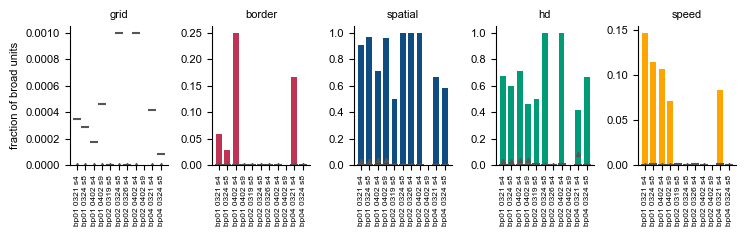

In [3]:
fig = sp.plot_class_counts(sessions)

## Border cells, and HD conjunction

In [4]:
u = units[units.eligible & ~units.narrow]
u[u.is_border][['recday', 'session', 'unit', 'border', 'border_wall', 'is_hd', 'pxd_r', 'rate_hz']]

,recday,session,unit,border,border_wall,is_hd,pxd_r,rate_hz
4,bp01_20240321_20240323,4,4,0.724952,right,True,0.249618,3.272531
27,bp01_20240321_20240323,4,27,0.706446,right,True,0.141186,3.061453
51,bp01_20240324_20240325,8,3,0.700658,right,True,0.090314,3.182648
99,bp01_20240402_20240403,4,3,0.756835,bottom,True,0.320722,1.660054
114,bp01_20240402_20240403,4,18,0.719879,bottom,False,0.174693,0.733255
116,bp01_20240402_20240403,4,20,0.669205,bottom,True,0.226239,1.953688
122,bp01_20240402_20240403,4,26,0.762968,left,False,0.142219,1.245870
130,bp01_20240402_20240403,4,34,0.679385,left,True,0.266873,3.936131
131,bp01_20240402_20240403,4,35,0.671546,left,True,0.151191,2.699661
135,bp01_20240402_20240403,4,39,0.662707,left,True,0.165417,3.426833


## Grid scores: the distribution against each session's pooled shuffle p95

In [5]:
rows = []
for f in sorted(glob.glob(f'{RUN}/shards/*.pkl')):
    sh = pickle.load(open(f, 'rb'))
    for s, ss in sh['sessions'].items():
        pb = np.array(ss['pools']['broad'], int)
        if len(pb):
            rows.append(dict(recday=sh['recday'], session=s, n=len(pb), p95=np.nanpercentile(ss['null']['grid'][:, pb], 95),
                             max_grid=np.nanmax(ss['real']['grid'][pb]), above_p95=int(np.nansum(ss['real']['grid'][pb] > np.nanpercentile(ss['null']['grid'][:, pb], 95)))))
pd.DataFrame(rows)

,recday,session,n,p95,max_grid,above_p95
0,bp01_20240321_20240323,4,34,0.509987,-0.001424,0
1,bp01_20240324_20240325,8,35,0.516399,0.376786,0
2,bp01_20240402_20240403,4,28,0.510201,0.356783,0
3,bp01_20240402_20240403,9,28,0.524937,0.421892,0
4,bp02_20240319_20240321,8,2,0.539297,-0.364471,0
5,bp02_20240324_20240325,8,1,0.437277,-0.663849,0
6,bp02_20240326_20240327,4,1,0.525856,-0.781472,0
7,bp02_20240402_20240403,4,1,0.467439,-0.118660,0
8,bp04_20240321_20240323,4,12,0.511665,0.020153,0
9,bp04_20240324_20240325,8,12,0.508820,0.792660,1


## Rotation between the two arena sessions of one sort (bp01 04-02 to 04-03)

In [6]:
rotations.T

,0,1
recday,bp01_20240402_20240403,bp02_20240402_20240403
mouse,bp01,bp02
s1,4,4
s2,9,9
ok,True,False
reason,NaN,0 units stable in both sessions
best,rot180,NaN
best_r,0.278713,NaN
second,flip_x,NaN
margin,0.208401,NaN


## Example gallery page (every unit is in the PDFs)

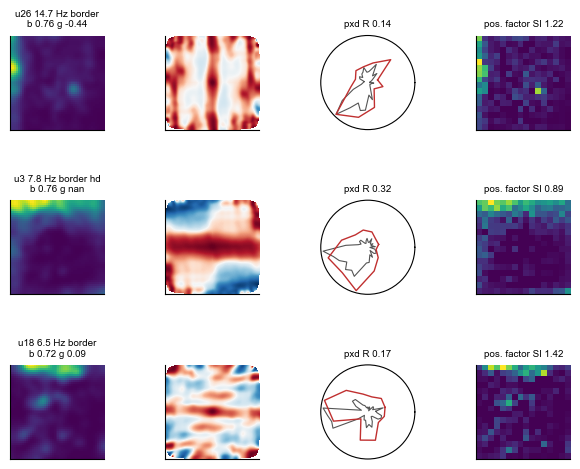

In [7]:
import matplotlib.pyplot as plt
sh = pickle.load(open(f'{RUN}/shards/bp01_20240402_20240403.pkl', 'rb'))
ss = sh['sessions'][4]
order = np.argsort(-np.nan_to_num(ss['real']['border'], nan=-9))[:3]
fig = plt.figure(figsize=(7.5, 5.5))
fig.subplots_adjust(hspace=0.75, wspace=0.35)
for row, u_ in enumerate(order):
    axs = [fig.add_subplot(3, 4, row * 4 + 1), fig.add_subplot(3, 4, row * 4 + 2),
           fig.add_subplot(3, 4, row * 4 + 3, projection='polar'), fig.add_subplot(3, 4, row * 4 + 4)]
    sp.plot_of_unit(axs, ss, u_)